# Phase I · 01 · What does our training data look like?

Before training, we compare REAL photos and FAKE images from CIFAKE. We want to know
whether differences in colour and fine detail could become useful cues for a detector.

We load **88,702 training-image measurements** and a small sample of the original pixels.
The saved files make the figures reproducible without downloading the full dataset.
`data/README.md` explains where they came from. This notebook only loads and visualizes data.

This notebook was prepared with AI assistance; the recorded data are unchanged.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
# This works when Jupyter opens either the repository or the phase1 folder.
try:
    from phase1 import helpers as h
# When this notebook is opened from phase1/, helpers is in the same folder.
except ModuleNotFoundError:
    import helpers as h
plt.ioff();  # Display each figure when all its panels are ready.


In [2]:
# Measurements cover the whole training split; previews are 12 of those same images.
data = h.load_saved("training_data_extra_bundle.npz")
preview = h.load_saved("training_preview.npz")
# Labels say REAL or FAKE; objects say things like cat, deer or ship.
labels, objects = data["labels"], data["objects"]
names = list(data["object_names"])
stats = data["stats"][:, :4]  # brightness, contrast, saturation, sharpness
# Use the same label colours in the data and model notebooks.
colors = {0: h.FAKE_COLOR, 1: h.REAL_COLOR}
print(f"FAKE: {(labels == 0).sum():,} · REAL: {(labels == 1).sum():,}")


FAKE: 43,702 · REAL: 45,000


## 1. Look at a few images first

We kept the official 20,000-image test set, removed 378 development/test overlaps and
920 repeated development copies, then reserved 5,000 images of each label for validation.
That leaves 43,702 FAKE and 45,000 REAL training images. Exact duplicates were found by
comparing decoded pixels; near-duplicates were not screened.

Below are six training images per label, sampled with seed 2026. The native size is only
32×32, so enlarging them reveals pixels rather than extra detail.


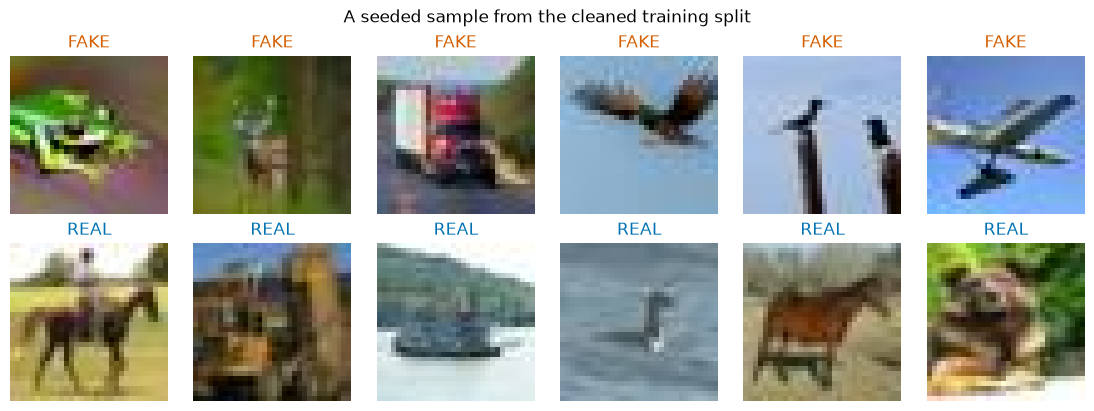

In [3]:
# Show the same fixed sample every time, with the correct label above each image.
fig, axes = plt.subplots(2, 6, figsize=(11, 4), layout="constrained")
for ax, image, label in zip(axes.flat, preview["images"], preview["labels"]):
    # Matplotlib needs height × width × colour, so move the colour axis to the end.
    ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
    ax.set_title("FAKE" if label == 0 else "REAL", color=colors[int(label)])
    # Pixel coordinates would only distract from these small examples.
    ax.axis("off")
fig.suptitle("A seeded sample from the cleaned training split")
h.show_plot()


The subjects look similar across labels, and both groups contain blurry or unclear
images. Twelve examples are not enough to establish a pattern, so we next use all training images.

## 2. Turn colour and detail into simple measurements

Brightness is mean luminance; contrast is its standard deviation. Saturation measures
the relative difference between colour channels. Sharpness is the variance of a small
Laplacian filter. It responds to fine detail, including noise, rather than visual quality.


In [4]:
# This is the calculation used for the four saved properties.
def image_properties(images):
    rgb = images.astype(np.float32) / 255
    # Combine the colour channels into one brightness image.
    luma = np.einsum("nchw,c->nhw", rgb, np.array([0.299, 0.587, 0.114], np.float32))
    # A larger gap between colour channels means stronger saturation.
    highest, lowest = rgb.max(axis=1), rgb.min(axis=1)
    saturation = np.divide(highest-lowest, highest, out=np.zeros_like(highest), where=highest > 0)
    # Compare each interior pixel with its neighbours to measure fine detail.
    laplacian = (luma[:, :-2, 1:-1] + luma[:, 2:, 1:-1]
                 + luma[:, 1:-1, :-2] + luma[:, 1:-1, 2:] - 4*luma[:, 1:-1, 1:-1])
    # Keep one row per image, in the same order as the saved measurements.
    return np.column_stack([luma.mean((1, 2)), luma.std((1, 2)),
                            saturation.mean((1, 2)), laplacian.var((1, 2))])

# Check the saved measurements against the pixels included in this submission.
measured = image_properties(preview["images"])
assert np.allclose(measured, stats[preview["indices"]], rtol=1e-5, atol=1e-7)


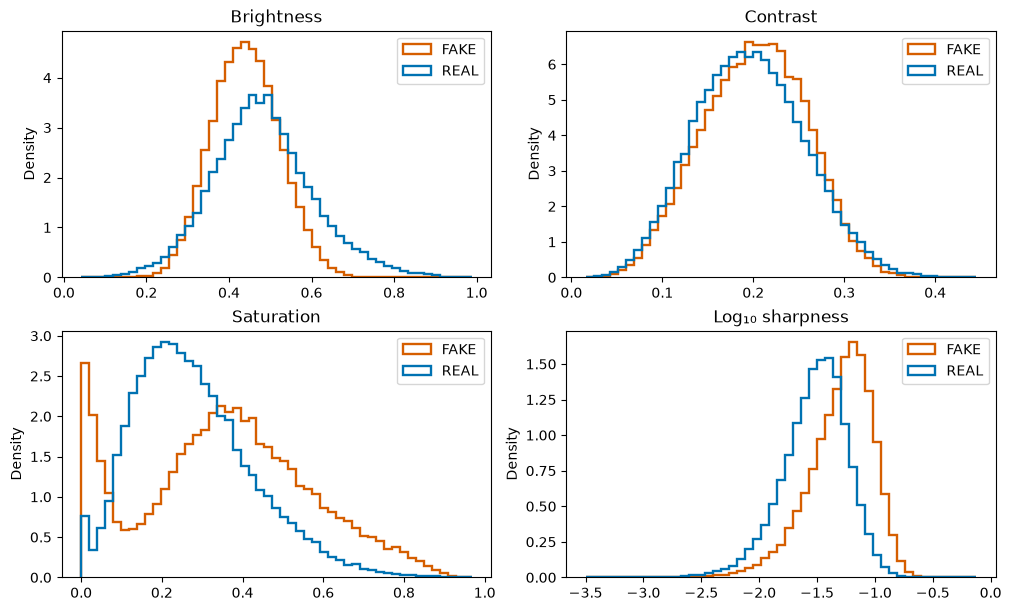

In [5]:
# Normalize each histogram because the labels have slightly different counts.
values = stats.copy()
# Sharpness has a long tail; a log scale makes the distributions easier to compare.
values[:, 3] = np.log10(values[:, 3] + 1e-8)
titles = ["Brightness", "Contrast", "Saturation", "Log₁₀ sharpness"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for column, ax in enumerate(axes.flat):
    # Give REAL and FAKE the same bin edges within this panel.
    bins = np.linspace(values[:, column].min(), values[:, column].max(), 50)
    for label, name in [(0, "FAKE"), (1, "REAL")]:
        # Density makes the areas comparable even though the label counts differ.
        ax.hist(values[labels == label, column], bins=bins, density=True,
                histtype="step", lw=1.7, color=colors[label], label=name)
    ax.set(title=titles[column], ylabel="Density")
    ax.legend()
h.show_plot()


The distributions overlap, but fake images tend to be more saturated and sharper.
That gives us a question for the models: do they still detect fakes after we remove fine detail?

## 3. Does that difference depend on the object?

We use the object names encoded in CIFAKE filenames only for analysis. The training split
was stratified by REAL/FAKE, not by object class. Each line below connects the two label medians.


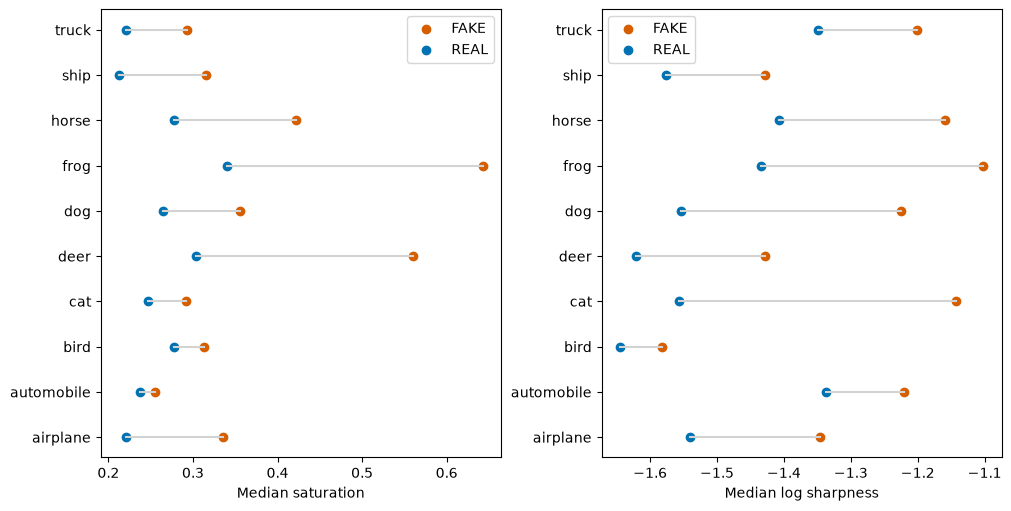

In [6]:
# Compare within each object class so its mix cannot explain the entire gap.
fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
for ax, column, title in zip(axes, [2, 3], ["Median saturation", "Median log sharpness"]):
    # Find a typical value for each label within each object class.
    medians = np.array([[np.median(values[(labels == label) & (objects == obj), column])
                         for obj in range(10)] for label in [0, 1]])
    for obj in range(10):
        # Each grey line joins the REAL and FAKE medians for one class.
        ax.plot(medians[:, obj], [obj, obj], color="lightgrey")
    for label, name in [(0, "FAKE"), (1, "REAL")]:
        ax.scatter(medians[label], range(10), color=colors[label], label=name)
    ax.set(yticks=range(10), yticklabels=names, xlabel=title)
    ax.legend()
h.show_plot()


The sharpness difference appears in every object class, while the colour difference is
much larger for some classes than others. The model notebooks follow this up with blur,
sharpening and reduced saturation.

## 4. What remains when we average the images?

Averaging removes individual subjects and leaves broad differences in colour and layout.
The saved means use every training image, not just the twelve previews.


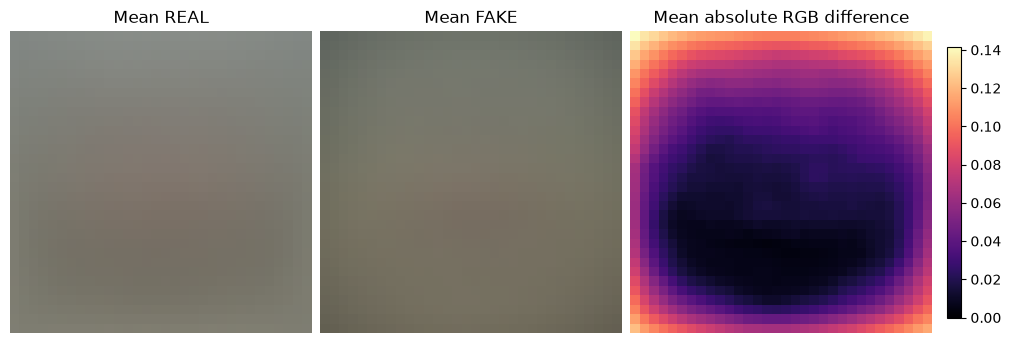

In [7]:
# Keep the difference on the original 0–1 pixel scale.
fake_mean, real_mean = data["mean_images"][:, 0]
# Average the absolute colour-channel gaps into one number per pixel.
difference = np.abs(fake_mean - real_mean).mean(axis=2)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
axes[0].imshow(real_mean)
axes[1].imshow(fake_mean)
# Brighter areas in this panel mean a larger gap between the two mean images.
heat = axes[2].imshow(difference, cmap="magma", vmin=0)
for ax, title in zip(axes, ["Mean REAL", "Mean FAKE", "Mean absolute RGB difference"]):
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(heat, ax=axes[2], shrink=0.8)
h.show_plot()


Fake images are darker on average, and the difference is more visible near the border.
This describes the dataset; it does not show where either model looks.

**What we take forward:** fine detail and colour are plausible cues, but neither separates
every real image from every fake. Next we train the CNN and fine-tune ResNet18, then change
the inputs while keeping each trained model fixed.
